In [1]:
from sklearn.datasets import make_classification
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

# 1. Generate a synthetic dataset
X, y = make_classification(
    n_samples=5000, n_features=20, n_informative=15, random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2. Initialize model with early stopping enabled
model = HistGradientBoostingClassifier(
    max_iter=500,  # Maximum boosting iterations (epochs)
    early_stopping=True,  # Enable early stopping
    validation_fraction=0.1,  # Hold out 10% of X_train for validation
    n_iter_no_change=10,  # Patience: stop after 10 iterations with no gain
    tol=1e-4,  # min_delta: minimum improvement threshold
    random_state=42,
)

# 3. Train and evaluate
model.fit(X_train, y_train)

print(f"Stopped at iteration: {model.n_iter_}")
print(f"Test Accuracy: {accuracy_score(y_test, model.predict(X_test)):.4f}")

Stopped at iteration: 147
Test Accuracy: 0.9580


In [3]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

# 1. Load and split dataset (Train / Validation / Test)
data = load_breast_cancer()
X, y = data.data, data.target

# Split into 70% train, 15% validation, 15% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

# 2. Scale features (fit ONLY on training data to prevent leakage)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# 3. Build the Keras model
model = models.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

model.compile(
    optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"]
)

# 4. Configure EarlyStopping callback
early_stop = EarlyStopping(
    monitor="val_loss",  # Metric to track
    patience=5,  # Stop after 5 epochs with no improvement
    min_delta=1e-4,  # Minimum change to count as an improvement
    mode="min",  # Look for minimum validation loss
    restore_best_weights=True,  # Revert model to best epoch's weights
    verbose=1,
)

# 5. Train the model
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,  # Upper bound; early stopping will halt before this
    batch_size=32,
    callbacks=[early_stop],
    verbose=1,
)

# 6. Evaluate the restored best model on unseen test data
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nStopped at epoch: {len(history.history['loss'])}")
print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.4f}")

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7563 - loss: 0.5305 - val_accuracy: 0.9412 - val_loss: 0.3889
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9472 - loss: 0.3135 - val_accuracy: 0.9647 - val_loss: 0.2391
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9648 - loss: 0.1995 - val_accuracy: 0.9765 - val_loss: 0.1565
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9648 - loss: 0.1472 - val_accuracy: 0.9765 - val_loss: 0.1168
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9724 - loss: 0.1163 - val_accuracy: 0.9765 - val_loss: 0.0938
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9799 - loss: 0.0907 - val_accuracy: 0.9765 - val_loss: 0.0807
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9774 - loss: 0.0864 - val_accuracy: 0.9882 - val_loss: 0.0706
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9824 - loss: 0.0760 - val_accuracy: 0.9882 - v

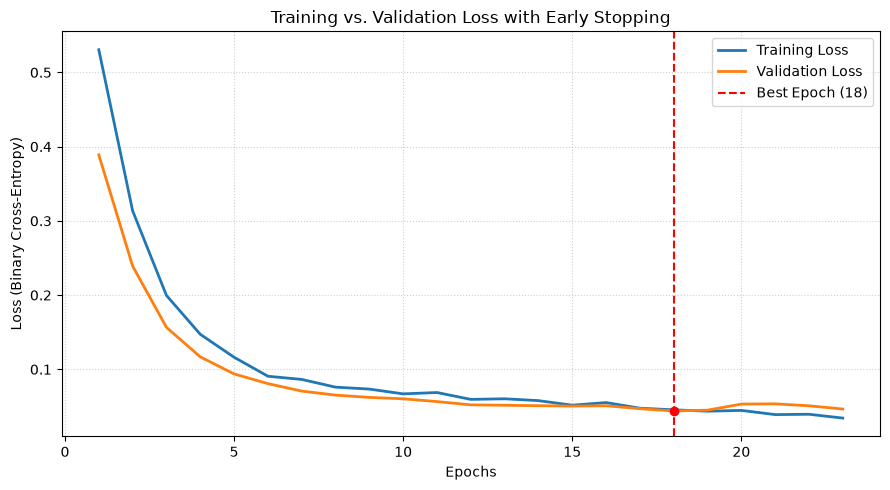

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# Extract loss values from the Keras history object
train_loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = range(1, len(train_loss) + 1)

# Find the epoch with the lowest validation loss (1-indexed)
best_epoch = np.argmin(val_loss) + 1
best_val_loss = val_loss[best_epoch - 1]

# Create the plot
plt.figure(figsize=(9, 5))
plt.plot(epochs, train_loss, label="Training Loss", linewidth=2)
plt.plot(epochs, val_loss, label="Validation Loss", linewidth=2)

# Mark the optimal stopping point (best restored weights)
plt.axvline(
    x=best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Epoch ({best_epoch})",
)
plt.scatter(best_epoch, best_val_loss, color="red", zorder=5)

plt.title("Training vs. Validation Loss with Early Stopping")
plt.xlabel("Epochs")
plt.ylabel("Loss (Binary Cross-Entropy)")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()